<a href="https://colab.research.google.com/github/dldustj0715/AI_study/blob/main/HAR/Exp2_CNN_Transformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCI HAR — Exp 2: CNN + Transformer Encoder
128×9 센서 입력에서 위치 정보와 Self-Attention을 사용하여 장거리 시점 간 관계를 학습

## 0. Drive 데이터 준비

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, zipfile
ZIP_PATH='/content/drive/MyDrive/Colab Notebooks/UCI HAR Dataset.zip'
DATASET_PATH='/content/UCI HAR Dataset'
required=f'{DATASET_PATH}/train/Inertial Signals/body_acc_x_train.txt'
if not os.path.isfile(required):
    assert os.path.isfile(ZIP_PATH), f'ZIP not found: {ZIP_PATH}'
    with zipfile.ZipFile(ZIP_PATH) as z: z.extractall('/content')
assert os.path.isfile(required), required
print('Dataset ready')

Mounted at /content/drive
Dataset ready


## 1. 데이터 로드 및 동일한 전처리

In [2]:
import random, numpy as np, tensorflow as tf, matplotlib.pyplot as plt, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras import layers, Model
SEED=42; VALIDATION_RATIO=.20; BATCH_SIZE=64; EPOCHS=100; LEARNING_RATE=.001
MODEL_PATH='best_cnn_transformer_uci_har.keras'
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
SIGNAL_NAMES=['body_acc_x','body_acc_y','body_acc_z','body_gyro_x','body_gyro_y','body_gyro_z','total_acc_x','total_acc_y','total_acc_z']
CLASS_NAMES=['WALKING','WALKING_UPSTAIRS','WALKING_DOWNSTAIRS','SITTING','STANDING','LAYING']
def load_signals(split):
    folder=f'{DATASET_PATH}/{split}/Inertial Signals'
    return np.stack([np.loadtxt(f'{folder}/{s}_{split}.txt',dtype=np.float32) for s in SIGNAL_NAMES],axis=-1)
def load_labels(split): return np.loadtxt(f'{DATASET_PATH}/{split}/y_{split}.txt',dtype=np.int32)-1
X_train_full,y_train_full=load_signals('train'),load_labels('train')
X_test,y_test=load_signals('test'),load_labels('test')
X_train,X_val,y_train,y_val=train_test_split(X_train_full,y_train_full,test_size=VALIDATION_RATIO,random_state=SEED,stratify=y_train_full)
scaler=StandardScaler().fit(X_train.reshape(-1,9))
def standardize(x): return scaler.transform(x.reshape(-1,9)).reshape(x.shape).astype(np.float32)
X_train,X_val,X_test=standardize(X_train),standardize(X_val),standardize(X_test)
print('Train',X_train.shape,'Val',X_val.shape,'Test',X_test.shape)

Train (5881, 128, 9) Val (1471, 128, 9) Test (2947, 128, 9)


## 2. 모델 구조

- **Conv1D kernel=7**: 가까운 시점의 국소 패턴 추출, 시간축 유지.
- **Learnable positional embedding**: 시점의 순서를 구분하도록 위치 정보 추가.
- **Transformer Encoder ×3**: Multi-Head Self-Attention으로 떨어진 시점의 관계 학습. Residual + LayerNorm + FFN 사용.
- **Global Average + Max Pooling**: 평균적 특성과 강한 반응을 함께 반영.

`(128,9) → Conv1D(128,64) → Positional Embedding → Transformer×3(128,64) → Avg+Max(128) → Dense(64) → Softmax(6)`

In [3]:
@tf.keras.utils.register_keras_serializable(package='HAR')
class PositionEmbedding(layers.Layer):
    def __init__(self,sequence_length=128,embedding_dim=64,**kwargs):
        super().__init__(**kwargs)
        self.sequence_length=sequence_length; self.embedding_dim=embedding_dim
        self.pos_emb=layers.Embedding(sequence_length,embedding_dim)
    def call(self,x):
        p=tf.range(tf.shape(x)[1]); return x+self.pos_emb(p)[tf.newaxis,:,:]
    def get_config(self): return {**super().get_config(),'sequence_length':self.sequence_length,'embedding_dim':self.embedding_dim}

def encoder(x,d_model=64,num_heads=4,ff_dim=128,dropout=.2):
    a=layers.LayerNormalization(epsilon=1e-6)(x)
    a=layers.MultiHeadAttention(num_heads=num_heads,key_dim=d_model//num_heads,dropout=dropout)(a,a)
    x=layers.Add()([x,layers.Dropout(dropout)(a)])
    f=layers.LayerNormalization(epsilon=1e-6)(x)
    f=layers.Dense(ff_dim,activation='gelu')(f)
    f=layers.Dropout(dropout)(f)
    f=layers.Dense(d_model)(f)
    return layers.Add()([x,layers.Dropout(dropout)(f)])

def build_model():
    inp=layers.Input(shape=(128,9))
    x=layers.Conv1D(64,7,padding='same',activation='relu')(inp)
    x=layers.LayerNormalization()(x)
    x=PositionEmbedding()(x)
    for _ in range(3): x=encoder(x)
    x=layers.LayerNormalization()(x)
    x=layers.Concatenate()([layers.GlobalAveragePooling1D()(x),layers.GlobalMaxPooling1D()(x)])
    x=layers.Dense(64,activation='relu')(x)
    x=layers.Dropout(.3)(x)
    return Model(inp,layers.Dense(6,activation='softmax')(x),name='CNN_Transformer_UCI_HAR')
model=build_model()
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
model.summary()

Model: "CNN_Transformer_UCI_HAR"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 9)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 128, 64)   │      4,096 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 128, 64)   │        128 │ conv1d[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ position_embedding  │ (None, 128, 64)   │      8,192 │ layer_normalizat… │
│ (PositionEmbedding) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 128, 64)   │        128 │ position_embeddi… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 128, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128, 64)   │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128, 64)   │          0 │ position_embeddi… │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 128, 64)   │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128, 128)  │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128, 64)   │      8,256 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128, 64)   │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 128, 64)   │          0 │ add[0][0],        │
│                     │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 128, 64)   │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 128, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 128, 64)   │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 128, 64)   │          0 │ add_1[0][0],      │
│                     │                   │            │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 128, 64)   │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                 

 Total params: 121,606 (475.02 KB)

 Trainable params: 121,606 (475.02 KB)

 Non-trainable params: 0 (0.00 B)

## 3. 학습 (Baseline과 동일한 학습 설정)

In [4]:
callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=15,restore_best_weights=True,verbose=1),tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor=.5,patience=5,min_lr=1e-6,verbose=1),tf.keras.callbacks.ModelCheckpoint(MODEL_PATH,monitor='val_loss',save_best_only=True,verbose=1)]
history=model.fit(X_train,y_train,validation_data=(X_val,y_val),epochs=EPOCHS,batch_size=BATCH_SIZE,callbacks=callbacks,verbose=1)
print('Best epoch:',np.argmin(history.history['val_loss'])+1)

Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.6321 - loss: 1.0997
Epoch 1: val_loss improved from None to 0.15414, saving model to best_cnn_transformer_uci_har.keras

Epoch 1: finished saving model to best_cnn_transformer_uci_har.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 55s 293ms/step - accuracy: 0.7973 - loss: 0.5829 - val_accuracy: 0.9531 - val_loss: 0.1541 - learning_rate: 0.0010
Epoch 2/100
91/92 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9378 - loss: 0.1782
Epoch 2: val_loss improved from 0.15414 to 0.11137, saving model to best_cnn_transformer_uci_har.keras

Epoch 2: finished saving model to best_cnn_transformer_uci_har.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 38s 18ms/step - accuracy: 0.9425 - loss: 0.1620 - val_accuracy: 0.9606 - val_loss: 0.1114 - learning_rate: 0.0010
Epoch 3/100
89/92 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9462 - loss: 0.1297
Epoch 3: val_loss did not improve from 0.11137
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9486 - loss: 0

## 4. Test 평가: Accuracy / Macro F1 / 클래스별 F1

In [5]:
model=tf.keras.models.load_model(MODEL_PATH)
test_loss,_=model.evaluate(X_test,y_test,batch_size=BATCH_SIZE,verbose=0)
y_pred=model.predict(X_test,batch_size=BATCH_SIZE,verbose=0).argmax(axis=1)
metrics={'Test Loss':test_loss,'Accuracy':accuracy_score(y_test,y_pred),'Macro Precision':precision_score(y_test,y_pred,average='macro'),'Macro Recall':recall_score(y_test,y_pred,average='macro'),'Macro F1':f1_score(y_test,y_pred,average='macro'),'Weighted F1':f1_score(y_test,y_pred,average='weighted')}
for k,v in metrics.items(): print(f'{k:18}: {v:.4f}')
print(classification_report(y_test,y_pred,target_names=CLASS_NAMES,digits=4))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'position_embedding', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Test Loss         : 0.3456
Accuracy          : 0.9386
Macro Precision   : 0.9413
Macro Recall      : 0.9388
Macro F1          : 0.9385
Weighted F1       : 0.9381
                    precision    recall  f1-score   support

           WALKING     0.9649    0.9980    0.9812       496
  WALKING_UPSTAIRS     0.9953    0.8917    0.9406       471
WALKING_DOWNSTAIRS     0.9333    1.0000    0.9655       420
           SITTING     0.9108    0.8106    0.8578       491
          STANDING     0.8435    0.9323    0.8857       532
            LAYING     1.0000    1.0000    1.0000       537

          accuracy                         0.9386      2947
         macro avg     0.9413    0.9388    0.9385      2947
      weighted avg     0.9407    0.9386    0.9381      2947



## 5. 기존 실험과 정량 비교

In [6]:
comparison=pd.DataFrame({'Metric':['Accuracy','Macro F1','Weighted F1','Test Loss'],'Baseline CNN+LSTM':[.9175,.9186,.9175,.4977],'Exp 1 InceptionTime':[.9427,.9429,.9425,.4439],'Exp 2 CNN+Transformer':[metrics['Accuracy'],metrics['Macro F1'],metrics['Weighted F1'],metrics['Test Loss']]})
display(comparison.round(4))
print('Macro F1 vs Baseline (percentage points):',round((metrics['Macro F1']-.9186)*100,2))
print('Macro F1 vs Exp 1 (percentage points):',round((metrics['Macro F1']-.9429)*100,2))

,Metric,Baseline CNN+LSTM,Exp 1 InceptionTime,Exp 2 CNN+Transformer
0,Accuracy,0.9175,0.9427,0.9386
1,Macro F1,0.9186,0.9429,0.9385
2,Weighted F1,0.9175,0.9425,0.9381
3,Test Loss,0.4977,0.4439,0.3456


Macro F1 vs Baseline (percentage points): 1.99
Macro F1 vs Exp 1 (percentage points): -0.44


## 6. 혼동행렬 및 학습곡선

SITTING -> STANDING: 91 STANDING -> SITTING: 36


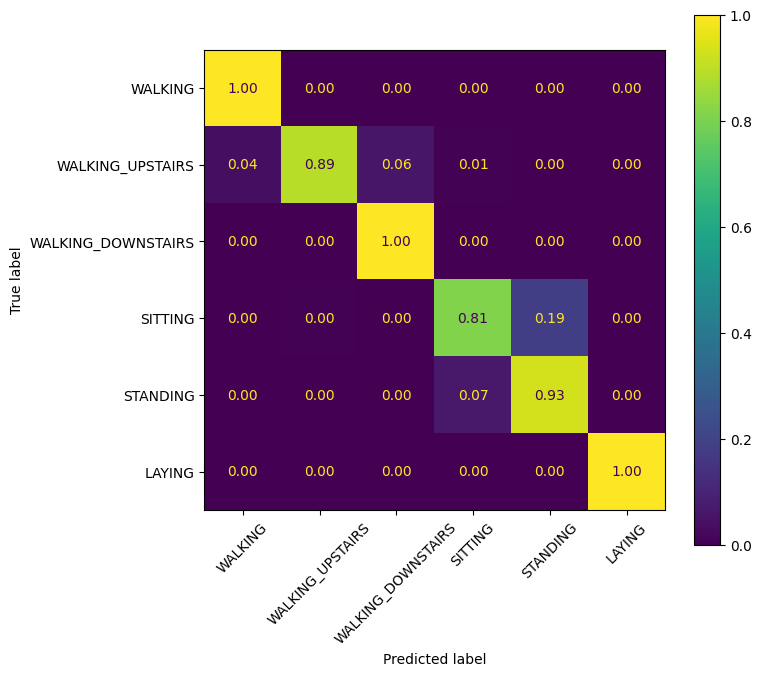

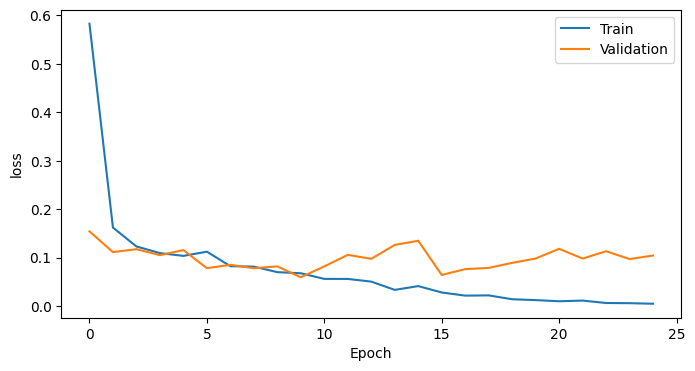

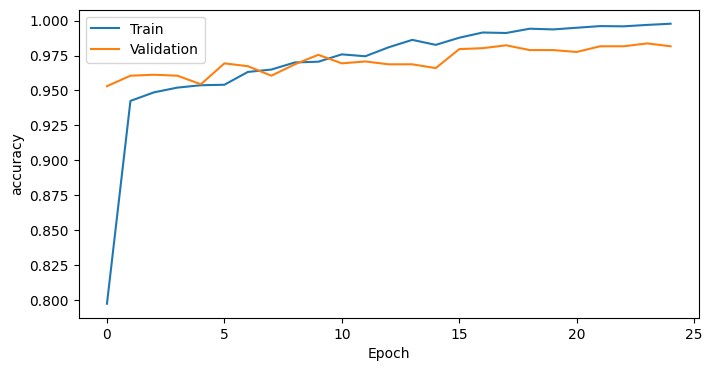

In [7]:
cm=confusion_matrix(y_test,y_pred)
print('SITTING -> STANDING:',cm[3,4],'STANDING -> SITTING:',cm[4,3])
fig,ax=plt.subplots(figsize=(8,7))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,display_labels=CLASS_NAMES,normalize='true',ax=ax,xticks_rotation=45,values_format='.2f')
fig.tight_layout();fig.savefig('exp2_confusion_matrix.png',dpi=300,bbox_inches='tight');plt.show()
for k,v in [('loss','val_loss'),('accuracy','val_accuracy')]:
    fig,ax=plt.subplots(figsize=(8,4));ax.plot(history.history[k],label='Train');ax.plot(history.history[v],label='Validation');ax.set(xlabel='Epoch',ylabel=k);ax.legend();plt.show()